# 📘 Explained copy — 02 Credit risk (Module 2)

Study copy of `notebooks/02_credit_risk.ipynb`. Original cells unchanged (with outputs); above each is an
**Explanation**: *what it does · why this method · input → output · how to read the output vs alternatives*.

**Story for the report.** 5,000 loans, 20% default. We engineer affordability ratios (EMI, payment-to-income, LTV),
compare logistic regression, random forest and gradient boosting with 5-fold stratified CV — **logistic regression wins
(CV AUC 0.729, test 0.746)** and is the most transparent. Platt calibration is tested (not needed: already calibrated).
Every loan gets an **out-of-fold PD**, grouped into 4 PD bands whose realised default rises 7% → 47%. We compute
**ECL = PD × LGD × EAD** (book ECL ₹63 cr = 9.8%), a risk-adjusted **expected net value** per loan, then choose the
approval PD cut-off (**PD < 0.11**) as the most valuable point that keeps approved-book ECL ≤ 3%. Result: Approve 836 /
Review 815 / Reject 3,349. Stress tests show the approved book breaches 3% under a 1.5× PD shock.

**Key numbers:** CV AUC 0.729 ± 0.011 · test AUC 0.746 · Gini ≈ 0.49 · KS ≈ 0.40 · approved ECL 2.82% ·
approved return ≈ 0.55% p.a.

> ### 📘 Explanation — cell 0
> **What it is.** Business question and chain: loans → PD model → ECL and risk-adjusted income → approve/review/reject → allocation rows for corporate and retail lending.
>
> **Why this chain.** It mirrors how banks actually do credit: **PD model (ML) → expected loss (Basel/IFRS 9 style
> ECL = PD·LGD·EAD) → pricing/profitability → decision under a risk appetite.**

# 02. Credit risk (Module 2)

**Business question.** Which loans should NovaFin approve, review or reject, how much credit loss should it expect, and how much does the loan book add to the ₹1,000 crore allocation decision?

**Chain.** Loan data → default model (PD) → expected credit loss and risk-adjusted income → approve / review / reject → allocation rows for **corporate lending** and **retail lending**.

**Plan.**
1. Audit and explore → 2. Features → 3. Split → 4. Compare models → 5. Check calibration → 6. Explain with SHAP → 7. Score the whole book out-of-sample → 8. PD bands → 9. ECL → 10. Risk-adjusted value → 11. Decision rule under a risk appetite → 12. Stress tests → 13. Risks → 14. Export.

> ### 📘 Explanation — cell 1
> **What it does.** Imports helpers and models (logistic, RF, HistGradientBoosting), `CalibratedClassifierCV` (Platt),
> sets LGD 0.40, cost of funds 6%, max ECL 3%; loads loans and creates `Loan_ID` = row number (file has none).
>
> **Output.** (5000, 15), default rate **0.199**.

In [1]:
import sys; sys.path.insert(0, '../src')
from novafin import *
RES, FIG = use_module('02')                 # this module's output folders (results/ and figures/)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.calibration import CalibratedClassifierCV
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
LGD, COF, MAX_ECL = ASSUMPTIONS['LGD'], ASSUMPTIONS['COST_OF_FUNDS'], ASSUMPTIONS['MAX_ECL_RATIO']
loans = load('loans')
loans.insert(0, 'Loan_ID', loans.index + 1)     # the brief asks for Loan_ID; the file only has Customer_ID
print(loans.shape, '| default rate:', round(loans.Default_Flag.mean(), 3))
loans.head()

NovaFin helpers loaded. Root: C:\Users\pravi\PG IITB\Machine Learning in Finance\capstone project solution\novafin_capstone
Outputs -> results/Module_02_Credit_Risk/ and figures/Module_02_Credit_Risk/


(5000, 15) | default rate: 0.199


,Loan_ID,Customer_ID,Customer_Type,Annual_Income,Employment_Length,Debt_to_Income,Credit_Score,Existing_Loan,Loan_Amount,Loan_Term_Months,Interest_Rate,Collateral_Value,Past_Default,Sector_Risk,Default_Flag
0,1,200001,Corporate,939967.04,29,0.248,698,1009401.25,1968503.82,12,8.96,2690085.58,0,65.31,0
1,2,200002,Retail,1629687.82,2,0.150,747,986482.96,1932554.81,12,7.82,2542892.81,0,33.98,0
2,3,200003,Corporate,1971716.74,18,0.300,718,1822182.57,815975.44,60,7.13,1202025.19,0,55.13,0
3,4,200004,Corporate,1848108.58,8,0.082,657,1169299.09,3855380.75,36,12.97,5571538.48,1,75.27,0
4,5,200005,Retail,673064.61,27,0.111,544,383728.34,749360.88,36,9.18,1272953.05,0,55.35,0


> ### 📘 Explanation — cell 2
> **Section header** – audit and EDA.

## 1. Audit and explore

> ### 📘 Explanation — cell 3
> **What it does.** Missing/duplicate count and summary statistics.
>
> **Output.** 0 missing, 0 duplicates. Income mean ₹10.5 lakh, credit score 406–850 (mean 689), DTI 0.03–0.85,
> loan amount mean ₹12.8 lakh, term 12–84 months.

In [2]:
print('Missing values:', int(loans.isna().sum().sum()), '| duplicate rows:', int(loans.duplicated().sum()))
loans.describe().T[['mean','min','50%','max']].round(2)

Missing values: 0 | duplicate rows: 0


,mean,min,50%,max
Loan_ID,2500.50,1.00,2500.50,5000.00
Customer_ID,202500.50,200001.00,202500.50,205000.00
Annual_Income,1051769.09,117044.78,910419.38,6728656.37
Employment_Length,15.46,1.00,15.00,30.00
Debt_to_Income,0.39,0.03,0.37,0.85
Credit_Score,688.62,406.00,690.00,850.00
Existing_Loan,655750.19,18024.37,514534.52,5253247.61
Loan_Amount,1279305.74,40522.67,999574.32,12085368.14
Loan_Term_Months,47.83,12.00,48.00,84.00
Interest_Rate,9.52,6.00,9.14,19.40


> ### 📘 Explanation — cell 4
> **What it does.** Domain range checks: credit score 300–900, DTI 0–1, loan > 0, interest 0–30%, Past_Default ∈ {0,1}.
>
> **Why.** Business-rule validation catches impossible values that a missing-value check would not. **Output:** 0 failures on all.

In [3]:
# Sanity checks on ranges (data quality, not imputation)
checks = {
 'Credit score outside 300-900': (~loans.Credit_Score.between(300, 900)).sum(),
 'Debt-to-income outside 0-1':   (~loans.Debt_to_Income.between(0, 1)).sum(),
 'Loan amount <= 0':             (loans.Loan_Amount <= 0).sum(),
 'Interest rate outside 0-30%':  (~loans.Interest_Rate.between(0, 30)).sum(),
 'Past_Default not 0/1':         (~loans.Past_Default.isin([0, 1])).sum(),
}
pd.Series(checks, name='rows failing')

Credit score outside 300-900    0
Debt-to-income outside 0-1      0
Loan amount <= 0                0
Interest rate outside 0-30%     0
Past_Default not 0/1            0
Name: rows failing, dtype: int64

> ### 📘 Explanation — cell 5
> **What it does.** Six bar charts of default rate by binned credit score, DTI, interest rate, sector risk, past default
> and customer type, with the portfolio average as a dashed line. Saves `credit_eda.png`.
>
> **Why this method.** Binned default rates ("bad rate by bucket") are the standard credit-scoring EDA — they show
> monotone relationships a scorecard should capture, and are easy for credit committees to read.
>
> **How to read.** Bars above the dashed line = riskier than average. Expected patterns: lower score / higher DTI /
> past default ⇒ more defaults. Interest rate shows the strongest pattern (next cell explains why).

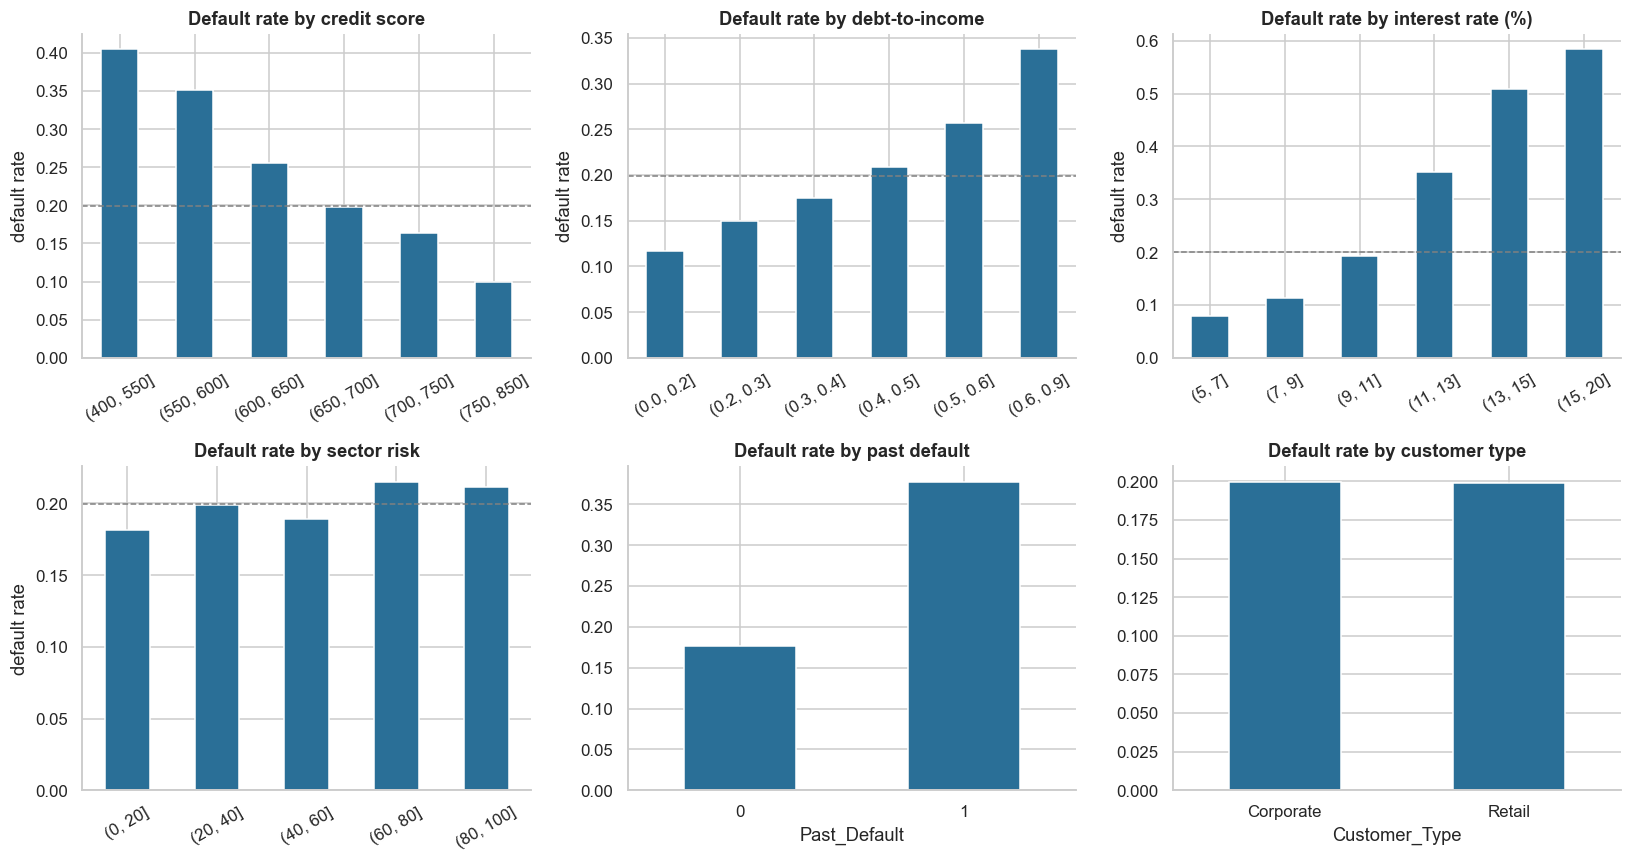

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
def rate_by(col, bins, a, title):
    g = loans.groupby(pd.cut(loans[col], bins), observed=True).Default_Flag.agg(['mean', 'size'])
    g['mean'].plot(kind='bar', ax=a, color='#2a6f97'); a.set_title(title); a.set_ylabel('default rate'); a.set_xlabel('')
    a.axhline(loans.Default_Flag.mean(), color='grey', ls='--', lw=1)
    a.tick_params(axis='x', rotation=30)
rate_by('Credit_Score', [400, 550, 600, 650, 700, 750, 850], ax[0,0], 'Default rate by credit score')
rate_by('Debt_to_Income', [0, .2, .3, .4, .5, .6, .9], ax[0,1], 'Default rate by debt-to-income')
rate_by('Interest_Rate', [5, 7, 9, 11, 13, 15, 20], ax[0,2], 'Default rate by interest rate (%)')
rate_by('Sector_Risk', [0, 20, 40, 60, 80, 100], ax[1,0], 'Default rate by sector risk')
loans.groupby('Past_Default').Default_Flag.mean().plot(kind='bar', ax=ax[1,1], color='#2a6f97'); ax[1,1].set_title('Default rate by past default'); ax[1,1].tick_params(axis='x', rotation=0)
loans.groupby('Customer_Type').Default_Flag.mean().plot(kind='bar', ax=ax[1,2], color='#2a6f97'); ax[1,2].set_title('Default rate by customer type'); ax[1,2].tick_params(axis='x', rotation=0)
plt.tight_layout(); savefig('credit_eda'); plt.show()

> ### 📘 Explanation — cell 6
> **Interpretation.** Interest rate predicts default because of **risk-based pricing** — the lender already charged risky
> borrowers more. It is known at origination (legitimate), but part of its signal is the lender's own past judgement.
> Section 4 tests the model without it.

**What to look for.** Defaults rise with lower credit scores, higher debt-to-income and past defaults, as expected. The strongest single pattern is with the **interest rate**: higher-rate loans default more. That is not a cause but a signal: the lender already charges more to riskier borrowers (risk-based pricing). It is known at origination, so using it is legitimate, but it means part of the model's skill is the lender's own earlier judgement. Section 4 tests this.

> ### 📘 Explanation — cell 7
> **Section header** – feature engineering; all new features are known at application (no leakage).

## 2. Features
Ratios usually carry more information than raw amounts. The new features are all known at application time (no leakage).

> ### 📘 Explanation — cell 8
> **What it does.** Adds:
> - **EMI** = L·r / (1 − (1+r)^−n) (standard amortising instalment, r = monthly rate);
> - **Payment_to_Income** = 12·EMI / income (repayment burden);
> - **Loan_to_Income**, **Total_Debt_to_Income** = (existing + new) / income;
> - **Loan_to_Value** = loan / collateral (lower = more cover);
> - **Corporate** dummy, **Log_Income**.
> Final feature set: 12 base + 4 engineered = **16 features**.
>
> **Why.** Default depends on *affordability* and *collateral cover*, which are ratios, not raw amounts. These are the
> standard credit underwriting ratios (DTI, LTV, payment burden).

In [5]:
def add_features(d):
    d = d.copy()
    r, n = d.Interest_Rate / 1200, d.Loan_Term_Months
    d['EMI'] = d.Loan_Amount * r / (1 - (1 + r) ** -n)                 # monthly instalment
    d['Payment_to_Income'] = d.EMI * 12 / d.Annual_Income             # annual repayment burden
    d['Loan_to_Income'] = d.Loan_Amount / d.Annual_Income
    d['Total_Debt_to_Income'] = (d.Existing_Loan + d.Loan_Amount) / d.Annual_Income
    d['Loan_to_Value'] = d.Loan_Amount / d.Collateral_Value           # lower = more collateral cover
    d['Corporate'] = (d.Customer_Type == 'Corporate').astype(int)
    d['Log_Income'] = np.log(d.Annual_Income)
    return d
data = add_features(loans)
BASE = ['Annual_Income','Employment_Length','Debt_to_Income','Credit_Score','Existing_Loan','Loan_Amount',
        'Loan_Term_Months','Interest_Rate','Collateral_Value','Past_Default','Sector_Risk','Corporate']
ENG = ['Payment_to_Income','Loan_to_Income','Total_Debt_to_Income','Loan_to_Value']
FEATURES = BASE + ENG
X, y = data[FEATURES], data.Default_Flag
print(len(FEATURES), 'features')

16 features


> ### 📘 Explanation — cell 9
> **Split design.** Stratified 80/20: both parts keep 20% defaults. Tune on train only; look at test once (avoid test-set overfitting).

## 3. Split
Stratified 80/20 so both parts keep the 20% default rate. Everything is tuned on the training part only. The 20% test part is looked at once, for final metrics.

> ### 📘 Explanation — cell 10
> **What it does.** `train_test_split(..., stratify=y)` and a 5-fold stratified CV object.
>
> **Output.** train (4000, 16), test (1000, 16), default rate 0.200 / 0.199.
>
> **Why not repeated CV here (unlike 01)?** With 5,000 rows (~1,000 defaults), a single stratified split + 5-fold CV is
> already stable (CV std ≈ 0.01), so repetition is unnecessary.

In [6]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
print('train', X_tr.shape, '| test', X_te.shape, '| default rate train/test:', round(y_tr.mean(), 3), round(y_te.mean(), 3))

train (4000, 16) | test (1000, 16) | default rate train/test: 0.2 0.199


> ### 📘 Explanation — cell 11
> **Header** – three models of increasing flexibility; logistic regression is the transparent benchmark credit committees know (scorecards).

## 4. Compare models
Three models of rising flexibility. The logistic regression is the transparent benchmark that credit committees are used to.

> ### 📘 Explanation — cell 12
> **What it does.** Defines logistic regression (with scaling), random forest (400 trees, min leaf 8), histogram gradient
> boosting (depth 3, lr 0.05, 250 iterations, L2 = 1). Runs 5-fold CV on the training set with ROC-AUC and PR-AUC.
>
> **Why these.** Linear (interpretable, regulatory standard) vs bagging vs boosting — the course's model ladder. Tree
> models are regularised (min leaf, depth, L2) to limit overfitting.
>
> **Output.** CV AUC: **Logistic 0.729 ± 0.011**, RF 0.706, GB 0.702. PR-AUC 0.403 / 0.393 / 0.376 (no-skill = 0.20).
>
> **How to read vs others.** The linear model wins by ~0.02 AUC ≈ 2× the fold std ⇒ relationships in this data are
> mostly **monotone and additive** (higher DTI → more risk), which logistic regression captures perfectly; trees add
> variance without extra signal.

In [7]:
models = {
 'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
 'Random forest':       RandomForestClassifier(n_estimators=400, min_samples_leaf=8, random_state=SEED, n_jobs=-1),
 'Gradient boosting':   HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=250, l2_regularization=1.0, random_state=SEED),
}
cvres = {}
for name, m in models.items():
    s = cross_validate(m, X_tr, y_tr, cv=cv, scoring=['roc_auc', 'average_precision'], n_jobs=-1)
    cvres[name] = {'CV ROC-AUC': s['test_roc_auc'].mean(), 'CV ROC-AUC std': s['test_roc_auc'].std(), 'CV PR-AUC': s['test_average_precision'].mean()}
cvres = pd.DataFrame(cvres).T
cvres.round(4)

,CV ROC-AUC,CV ROC-AUC std,CV PR-AUC
Logistic regression,0.7294,0.0112,0.4033
Random forest,0.7057,0.0128,0.3932
Gradient boosting,0.7024,0.0123,0.3764


> ### 📘 Explanation — cell 13
> **What it does.** Fits each model on the full training set and evaluates on the untouched test set with
> `binary_report` (ROC-AUC, Gini, KS, PR-AUC, calibration gap, mean predicted vs actual).
>
> **Output.** Test AUC: Logistic **0.746**, RF 0.752, GB 0.745; Gini ≈ 0.49–0.50; KS ≈ 0.39–0.41; calibration gap 0.031 /
> 0.032 / 0.012.
>
> **How to read.** On one test split the three are within 0.007 AUC — inside noise. **Gini** (= 2·AUC − 1) and **KS**
> are the industry credit metrics: Gini ≈ 0.5 and KS ≈ 0.4 are typical of a decent retail scorecard. CV (5 folds) is a
> more reliable basis for choosing than one test split.

In [8]:
fitted = {n: m.fit(X_tr, y_tr) for n, m in models.items()}
test_rep = pd.DataFrame({n: binary_report(y_te, m.predict_proba(X_te)[:, 1], n) for n, m in fitted.items()}).T
test_rep.round(4)

,ROC-AUC,Gini,KS,PR-AUC,Calib. gap,Mean predicted,Actual rate
Logistic regression,0.7459,0.4918,0.3964,0.4328,0.0313,0.2089,0.199
Random forest,0.7517,0.5034,0.4102,0.4372,0.0322,0.2138,0.199
Gradient boosting,0.7452,0.4904,0.3918,0.4242,0.0120,0.2072,0.199


> ### 📘 Explanation — cell 14
> **Reading guide.** If models are within CV noise, the simpler wins. PR-AUC must be compared with 0.20 (the random baseline), not with 0.

**Reading this.** If the three models are within the cross-validation noise (see the std column) of each other, extra complexity is not buying anything and the simpler model should win. PR-AUC should be compared with the default rate (20%), which is what a random model would score.

### Does the model still work without the interest rate?

> ### 📘 Explanation — cell 15
> **What it does.** Re-runs CV for every model **without `Interest_Rate`** and reports the AUC drop.
>
> **Why.** A leakage/robustness test: if the model relied on the lender's own pricing, it would just be copying past
> judgement (and could not be used to *set* prices).
>
> **Output.** Drop: logistic 0.0001, RF −0.003, GB −0.005 (they even improve).
>
> **How to read.** The rate's information is already contained in credit score, DTI etc. ⇒ the model does **not** lean on
> pricing. Rate is kept (it is known at application).

In [9]:
no_rate = [f for f in FEATURES if f != 'Interest_Rate']
rows = {}
for name, m in models.items():
    full = cross_validate(m, X_tr, y_tr, cv=cv, scoring='roc_auc', n_jobs=-1)['test_score'].mean()
    wo = cross_validate(m, X_tr[no_rate], y_tr, cv=cv, scoring='roc_auc', n_jobs=-1)['test_score'].mean()
    rows[name] = {'with Interest_Rate': full, 'without Interest_Rate': wo, 'drop': full - wo}
pd.DataFrame(rows).T.round(4)

,with Interest_Rate,without Interest_Rate,drop
Logistic regression,0.7294,0.7292,0.0001
Random forest,0.7057,0.7086,-0.0029
Gradient boosting,0.7024,0.7076,-0.0052


> ### 📘 Explanation — cell 16
> **Result + why calibration matters.** PD multiplies directly into expected loss, so it must be a *believable probability*, not just a good ranking. A model can have high AUC and still say 40% when truth is 20%.

**Result.** Removing the interest rate barely changes the AUC (for the logistic regression the change is in the fourth decimal; for the tree models it even improves slightly). So the model does **not** lean on pricing: the rate's information is already contained in credit score, debt-to-income and the other features. The rate stays in, because it is known at application. A model used to *set* prices should still never take the price as an input.

## 5. Choose a model and check calibration
**PD must be a believable probability**, because it multiplies straight into expected loss. A model can rank well (high AUC) and still say 40% when the truth is 20%.

> ### 📘 Explanation — cell 17
> **What it does.** Applies the selection rule: best CV AUC, but prefer the simplest model within 0.005 AUC.
>
> **Output.** Best = chosen = **Logistic regression** (no trade-off: best and simplest).

In [10]:
# Rule: take the best CV AUC, but prefer the simpler model unless the complex one wins by more than 0.005
best = cvres['CV ROC-AUC'].idxmax()
chosen = best
order = ['Logistic regression', 'Random forest', 'Gradient boosting']
for simple in order:
    if cvres.loc[best, 'CV ROC-AUC'] - cvres.loc[simple, 'CV ROC-AUC'] <= 0.005:
        chosen = simple; break
print('Best by CV AUC :', best)
print('Chosen (simplest within 0.005 AUC):', chosen)

Best by CV AUC : Logistic regression
Chosen (simplest within 0.005 AUC): Logistic regression


> ### 📘 Explanation — cell 18
> **Header** – comparison table: gain vs no-skill (AUC 0.5, PR-AUC 0.20) and gap to best, with test metrics for context.

### Model comparison: what do we gain by choosing one model over another?
`Gain vs baseline` = improvement over a **no-skill** model (AUC 0.5, PR-AUC = the 20% default rate).
`Gap to best` = how far each model trails the winner. Test-set metrics are added for context.

> ### 📘 Explanation — cell 19
> **What it does.** Builds the ranked comparison via `compare_models()` with CV and test metrics and a no-skill row.
>
> **Output.** Logistic: +0.229 AUC over no-skill, gap 0; RF gap 0.024; GB gap 0.027.
>
> **Why it matters.** Quantifies "what do we gain by choosing this model": +0.23 AUC over guessing, and nothing lost
> versus the more complex models.

In [11]:
table = cvres.copy()                                                            # CV results on the training part
table['Test ROC-AUC'] = test_rep['ROC-AUC']                                     # untouched test set
table['Test calib. gap'] = test_rep['Calib. gap']                              # |predicted - observed| by decile (lower = better)
table.loc['No-skill (base rate)'] = [0.5, 0.0, y.mean(), 0.5, 0.0]
compare_models(table, 'CV ROC-AUC', chosen=chosen, baseline='No-skill (base rate)',
               extra=['CV ROC-AUC std', 'CV PR-AUC', 'Test ROC-AUC', 'Test calib. gap']).round(4)

,Rank,CV ROC-AUC,CV ROC-AUC std,CV PR-AUC,Test ROC-AUC,Test calib. gap,Gain vs baseline,Gap to best,Chosen
Logistic regression,1,0.7294,0.0112,0.4033,0.7459,0.0313,0.2294,0.0000,✔
Random forest,2,0.7057,0.0128,0.3932,0.7517,0.0322,0.2057,0.0237,
Gradient boosting,3,0.7024,0.0123,0.3764,0.7452,0.0120,0.2024,0.0270,
No-skill (base rate),4,0.5000,0.0000,0.1994,0.5000,0.0000,0.0000,0.2294,


> ### 📘 Explanation — cell 20
> **Benefit of the choice.** Logistic regression is best on CV *and* simplest → wins on accuracy and transparency (readable coefficients for regulators, well-calibrated PDs).

**Benefit of the choice.** All three models gain about +0.20 to +0.23 AUC over no skill. Logistic regression is the **best** on cross-validation (0.729 vs 0.706 for random forest and 0.702 for gradient boosting, a gap of about twice the fold-to-fold spread) **and** the simplest, so there is no trade-off: it wins on accuracy and on transparency (coefficients a credit committee and a regulator can read, and well-calibrated PDs). On the single test split the three are within 0.007 AUC of each other.

> ### 📘 Explanation — cell 21
> **What it does.** Wraps the chosen model in `CalibratedClassifierCV(method='sigmoid', cv=5)` = **Platt scaling**
> (a logistic fit of outcome on score, learned within CV). Compares raw vs calibrated on test; plots calibration curve
> (8 bins), ROC curves and precision–recall curves for all models. Saves `credit_model_curves.png`.
>
> **Why Platt.** It is the taught calibration method and suits models with monotone but distorted scores (e.g. trees).
>
> **Output.** Raw calibration gap 0.031 vs calibrated 0.034; AUC unchanged (0.746).
>
> **How to read.** Calibration made it slightly *worse* — expected, because logistic regression already outputs
> calibrated probabilities (it is fitted by maximum likelihood on log-loss). So the raw model is kept. ROC curves
> overlap ⇒ similar ranking; PR curves sit well above the 0.20 baseline.

,ROC-AUC,Gini,KS,PR-AUC,Calib. gap,Mean predicted,Actual rate
uncalibrated,0.7459,0.4918,0.3964,0.4328,0.0313,0.2089,0.199
calibrated,0.7457,0.4914,0.3976,0.4324,0.0336,0.2085,0.199


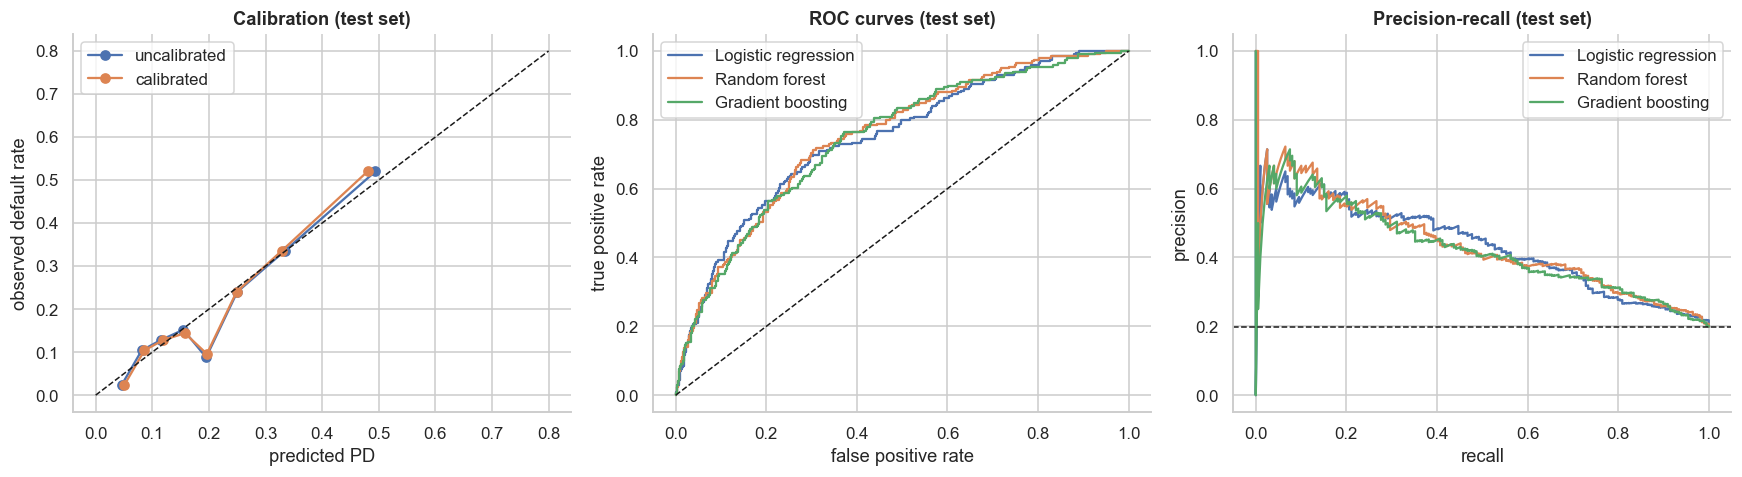

In [12]:
base_model = models[chosen]
cal_model = CalibratedClassifierCV(base_model, method='sigmoid', cv=5)    # Platt scaling inside CV
cal_model.fit(X_tr, y_tr)
p_raw = fitted[chosen].predict_proba(X_te)[:, 1]
p_cal = cal_model.predict_proba(X_te)[:, 1]
cmp = pd.DataFrame({'uncalibrated': binary_report(y_te, p_raw), 'calibrated': binary_report(y_te, p_cal)}).T
display(cmp.round(4))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for p, lab in [(p_raw, 'uncalibrated'), (p_cal, 'calibrated')]:
    t = calibration_table(y_te, p, 8); ax[0].plot(t.predicted, t.observed, 'o-', label=lab)
ax[0].plot([0, .8], [0, .8], 'k--', lw=1); ax[0].set_xlabel('predicted PD'); ax[0].set_ylabel('observed default rate'); ax[0].set_title('Calibration (test set)'); ax[0].legend()
for n, m in fitted.items():
    fpr, tpr, _ = roc_curve(y_te, m.predict_proba(X_te)[:, 1]); ax[1].plot(fpr, tpr, label=n)
ax[1].plot([0, 1], [0, 1], 'k--', lw=1); ax[1].set_title('ROC curves (test set)'); ax[1].set_xlabel('false positive rate'); ax[1].set_ylabel('true positive rate'); ax[1].legend()
for n, m in fitted.items():
    pr, rc, _ = precision_recall_curve(y_te, m.predict_proba(X_te)[:, 1]); ax[2].plot(rc, pr, label=n)
ax[2].axhline(y_te.mean(), color='k', ls='--', lw=1); ax[2].set_title('Precision-recall (test set)'); ax[2].set_xlabel('recall'); ax[2].set_ylabel('precision'); ax[2].legend()
plt.tight_layout(); savefig('credit_model_curves'); plt.show()

> ### 📘 Explanation — cell 22
> **Rule:** use the calibrated model only if it lowers the calibration gap. **SHAP section:** regulators need to know *why* a loan scores high.

If calibration lowers the calibration gap (average |predicted − observed| across deciles; lower is better) and brings the curve closer to the diagonal, the calibrated model is used for everything below. Otherwise the raw model is kept.

## 6. Explain the model with SHAP
Regulators and credit committees need to know *why* a loan scores high. SHAP gives each feature's push on each loan's PD.

> ### 📘 Explanation — cell 23
> **What it does.** Selects the final model (here: **uncalibrated** logistic), computes model-agnostic SHAP on 250 test
> loans with 100 training loans as background, draws the beeswarm and prints mean |SHAP| ranking. Saves `credit_shap.png`.
>
> **Output (mean |SHAP| on PD).** Debt_to_Income **0.065**, Loan_Amount 0.061, Credit_Score 0.059, Past_Default 0.033,
> Total_Debt_to_Income 0.023, Annual_Income 0.017, Loan_to_Value 0.010.
>
> **How to read.** Affordability (DTI), size of exposure and credit score dominate, then past default — all economically
> sensible, which is what a credit committee wants to see. The progress bar is SHAP's permutation explainer.

Using uncalibrated Logistic regression


PermutationExplainer explainer:  69%|██████▉   | 172/250 [00:00<?, ?it/s]

PermutationExplainer explainer:  70%|███████   | 175/250 [00:10<00:04, 18.68it/s]

PermutationExplainer explainer:  71%|███████   | 177/250 [00:10<00:04, 15.20it/s]

PermutationExplainer explainer:  72%|███████▏  | 179/250 [00:10<00:04, 15.34it/s]

PermutationExplainer explainer:  72%|███████▏  | 181/250 [00:10<00:04, 15.74it/s]

... (32 outputs left out)

PermutationExplainer explainer:  99%|█████████▉| 247/250 [00:14<00:00, 14.62it/s]

PermutationExplainer explainer: 100%|█████████▉| 249/250 [00:14<00:00, 14.60it/s]

PermutationExplainer explainer: 251it [00:15, 14.73it/s]                         

PermutationExplainer explainer: 251it [00:15,  5.25it/s]

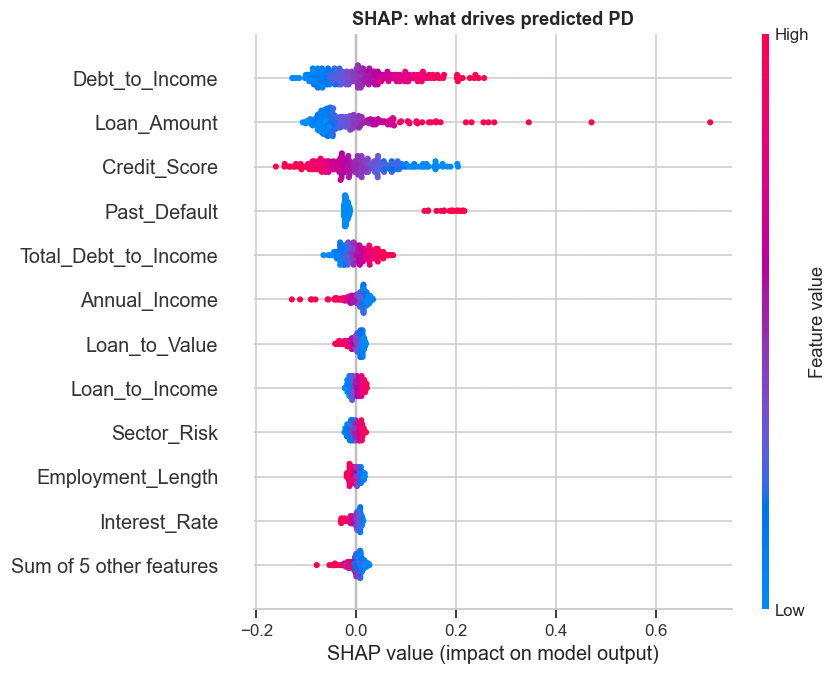

Debt_to_Income          0.0648
Loan_Amount             0.0605
Credit_Score            0.0585
Past_Default            0.0330
Total_Debt_to_Income    0.0231
Annual_Income           0.0168
Loan_to_Value           0.0103
Loan_to_Income          0.0091
dtype: float64

In [13]:
use_cal = cmp.loc['calibrated', 'Calib. gap'] <= cmp.loc['uncalibrated', 'Calib. gap']
final_model = cal_model if use_cal else fitted[chosen]
print('Using', 'calibrated' if use_cal else 'uncalibrated', chosen)
rng = np.random.RandomState(SEED)
bg = X_tr.sample(100, random_state=SEED); ex = X_te.sample(250, random_state=SEED)
import shap
sv = shap_importance(lambda d: final_model.predict_proba(pd.DataFrame(d, columns=FEATURES))[:, 1], bg, ex)
shap.plots.beeswarm(sv, max_display=12, show=False); plt.title('SHAP: what drives predicted PD'); plt.tight_layout(); savefig('credit_shap'); plt.show()
imp = pd.Series(np.abs(sv.values).mean(0), index=FEATURES).sort_values(ascending=False)
imp.head(8).round(4)

> ### 📘 Explanation — cell 24
> **Reading the beeswarm + why out-of-fold scoring.** Red (high value) left of zero = high value lowers PD (e.g. credit score). For portfolio losses every loan needs a PD from a model that **did not train on it**; in-sample PDs would understate risk.

**How to read the plot.** Each dot is a loan. Right of zero means the feature pushed the PD up; red means a high feature value. A credit score that is high (red) sitting on the left means good scores lower PD, as it should. If a driver surprises you, check it before trusting the model.

## 7. Score the whole book out-of-sample
To compute portfolio losses we need a PD for **all 5,000 loans**. Scoring loans with a model that has already seen them would understate risk, so every loan is scored by a model that did not train on it (5-fold out-of-fold predictions).

> ### 📘 Explanation — cell 25
> **What it does.** `cross_val_predict` with 5 folds → out-of-fold PD for all 5,000 loans; reports metrics and PD distribution.
>
> **Output.** OOF AUC **0.733**, Gini 0.465, KS 0.350, **calibration gap 0.008**, mean PD 0.1997 vs actual 0.1994.
> PD ranges 0.012 – 0.857, median 0.16.
>
> **How to read.** Mean PD ≈ actual default rate and a tiny calibration gap ⇒ PDs can be used directly in ECL.

In [14]:
pd_oof = cross_val_predict(CalibratedClassifierCV(models[chosen], method='sigmoid', cv=5) if use_cal else models[chosen],
                           X, y, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
data['PD'] = pd_oof
print(binary_report(y, pd_oof, 'out-of-fold, all loans').round(4))
print('\nPD summary:'); print(data.PD.describe().round(3))

ROC-AUC           0.7325
Gini              0.4649
KS                0.3503
PR-AUC            0.4045
Calib. gap        0.0081
Mean predicted    0.1997
Actual rate       0.1994
Name: out-of-fold, all loans, dtype: float64

PD summary:
count    5000.000
mean        0.200
std         0.143
min         0.012
25%         0.094
50%         0.160
75%         0.268
max         0.857
Name: PD, dtype: float64


> ### 📘 Explanation — cell 26
> **PD bands design.** Cut-offs relative to the 20% portfolio rate (≈ ½×, 1×, 1¾×): 10 / 20 / 35%. Bands must show realised default rising step by step (monotonicity).

## 8. PD bands
Bands turn a probability into something a credit officer can act on. The cut-offs are set relative to the portfolio default rate (about 20%): roughly **half**, **one times** and **one and three-quarter times** the average. The check below confirms the **realised default rate rises step by step** across bands, which is what makes the bands trustworthy.

> ### 📘 Explanation — cell 27
> **What it does.** Buckets PD into A (<10%), B (10–20%), C (20–35%), D (>35%) and reports count, mean PD, **realised**
> default, exposure and share.
>
> **Output.** A: 1,387 loans, PD 6.6% vs realised 7.2% · B: 1,681, 14.6% vs 14.1% · C: 1,196, 26.2% vs 26.4% ·
> D: 736, 47.2% vs 46.7%.
>
> **How to read.** Predicted ≈ realised in every band and strictly increasing ⇒ a valid rating scale (discriminates and is calibrated).

In [15]:
base_rate = y.mean()
cuts = [0, 0.10, 0.20, 0.35, 1.0]
labels = ['A: Low', 'B: Moderate', 'C: Elevated', 'D: High']
data['PD_Band'] = pd.cut(data.PD, cuts, labels=labels, include_lowest=True)
band = data.groupby('PD_Band', observed=True).agg(loans=('PD', 'size'), mean_PD=('PD', 'mean'),
                                                  realised_default=('Default_Flag', 'mean'),
                                                  exposure_cr=('Loan_Amount', lambda s: cr(s.sum())))
band['share_of_loans'] = band.loans / band.loans.sum()
band.round(3)

,loans,mean_PD,realised_default,exposure_cr,share_of_loans
PD_Band,,,,,
A: Low,1387,0.066,0.072,112.175,0.277
B: Moderate,1681,0.146,0.141,197.363,0.336
C: Elevated,1196,0.262,0.264,184.064,0.239
D: High,736,0.472,0.467,146.051,0.147


> ### 📘 Explanation — cell 28
> **What it does.** Bar chart of predicted vs realised default per band (`credit_bands.png`) — the visual proof of the table above.

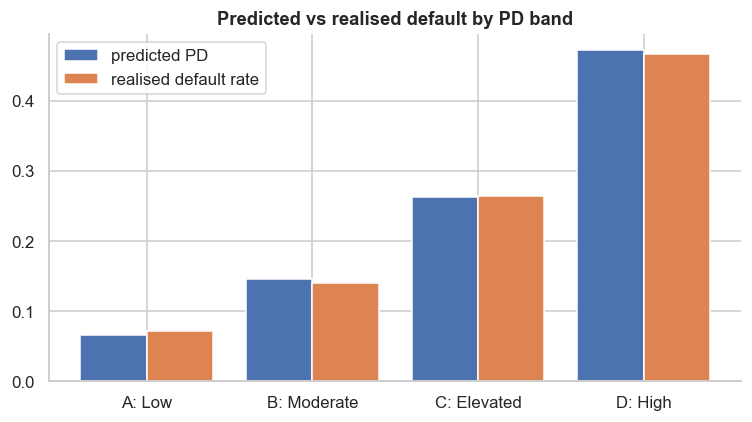

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(band)); ax.bar(x - .2, band.mean_PD, .4, label='predicted PD'); ax.bar(x + .2, band.realised_default, .4, label='realised default rate')
ax.set_xticks(x); ax.set_xticklabels(band.index); ax.set_title('Predicted vs realised default by PD band'); ax.legend(); plt.tight_layout(); savefig('credit_bands'); plt.show()

> ### 📘 Explanation — cell 29
> **Header** – compare the brief's illustrative bands (5/15/30%) with ours (10/20/35%).

### Brief's illustrative bands (5 / 15 / 30%) vs our bands (10 / 20 / 35%)
The brief asks us to justify the PD bands rather than copy them. The table puts both side by side on the same
out-of-fold PDs.

> ### 📘 Explanation — cell 30
> **What it does.** Applies both banding schemes to the same OOF PDs and tabulates count, mean PD, realised default, share.
>
> **Output.** Brief bands: Low <5% holds only **6.8%** of loans; ours spread loans 28% / 34% / 24% / 15%.
>
> **Why ours.** With a 20% average default rate, a "<5%" band is nearly empty and useless for decisions. Bands relative
> to the portfolio's own rate use the full scale while staying monotone (7% → 47%).

In [17]:
brief = pd.cut(data.PD, [0, 0.05, 0.15, 0.30, 1.0], labels=['Low <5%', 'Medium 5-15%', 'High 15-30%', 'Very High >30%'], include_lowest=True)
ours = data.PD_Band                                                                 # our bands from above
def band_table(b, name):
    t = data.groupby(b, observed=False).agg(Loans=('PD', 'size'), Mean_PD=('PD', 'mean'), Realised_default=('Default_Flag', 'mean'))
    t['Share of loans'] = t.Loans / len(data)
    t.index = [f'{name}: {i}' for i in t.index]
    return t
pd.concat([band_table(brief, 'Brief bands'), band_table(ours, 'Our bands')]).round(3)

,Loans,Mean_PD,Realised_default,Share of loans
Brief bands: Low <5%,342,0.038,0.032,0.068
Brief bands: Medium 5-15%,1965,0.098,0.099,0.393
Brief bands: High 15-30%,1682,0.212,0.209,0.336
Brief bands: Very High >30%,1011,0.432,0.435,0.202
Our bands: A: Low,1387,0.066,0.072,0.277
Our bands: B: Moderate,1681,0.146,0.141,0.336
Our bands: C: Elevated,1196,0.262,0.264,0.239
Our bands: D: High,736,0.472,0.467,0.147


> ### 📘 Explanation — cell 31
> **Justification text** for the band choice (use in report).

**Why our bands.** With a 20% average default rate, the brief's *Low < 5%* band holds only about 7% of loans, so it would help a credit officer very little. Bands set relative to the portfolio's own default rate (½×, 1×, 1¾×) spread the loans across all four groups (28% / 34% / 24% / 15%), and realised default still rises steadily from band A (7%) to band D (47%), which is the property a rating scale must have.

> ### 📘 Explanation — cell 32
> **ECL formula.** ECL = PD × LGD × EAD. PD = OOF probability, LGD = 40% (given), EAD = loan amount (conservative: ignores amortisation). This is the IFRS 9 / Basel expected-loss concept.

## 9. Expected credit loss
$$ECL = PD \times LGD \times EAD$$
- **PD:** the out-of-fold probability above.
- **LGD:** 40% (given in the brief).
- **EAD:** the loan amount. (Simplification: it ignores amortisation, so it is a conservative measure of exposure at default.)

> ### 📘 Explanation — cell 33
> **What it does.** Computes ECL per loan and totals for the whole book and by customer type.
>
> **Output.** Book exposure **₹639.7 cr**, ECL **₹62.9 cr = 9.83%** of exposure; Corporate 10.1%, Retail 9.7%.
>
> **How to read.** A ~10% expected loss is very high (synthetic book with 20% defaults) ⇒ lending the whole book would
> not be profitable; selection is essential.

In [18]:
data['EAD'] = data.Loan_Amount
data['ECL'] = data.PD * LGD * data.EAD
tot = pd.DataFrame({'Loans': [len(data)], 'Mean PD': [data.PD.mean()], 'Exposure (₹ cr)': [cr(data.EAD.sum())], 'ECL (₹ cr)': [cr(data.ECL.sum())], 'ECL % of exposure': [100 * data.ECL.sum() / data.EAD.sum()]}, index=['Whole book'])
by_type = data.groupby('Customer_Type').agg(**{'Loans': ('PD', 'size'), 'Mean PD': ('PD', 'mean'), 'Exposure (₹ cr)': ('EAD', lambda s: cr(s.sum())), 'ECL (₹ cr)': ('ECL', lambda s: cr(s.sum()))})
by_type['ECL % of exposure'] = 100 * by_type['ECL (₹ cr)'] / by_type['Exposure (₹ cr)']
pd.concat([tot, by_type]).round(2)

,Loans,Mean PD,Exposure (₹ cr),ECL (₹ cr),ECL % of exposure
Whole book,5000,0.2,639.65,62.89,9.83
Corporate,1306,0.2,173.22,17.53,10.12
Retail,3694,0.2,466.43,45.36,9.72


> ### 📘 Explanation — cell 34
> **What it does.** ECL by PD band.
>
> **Output.** ECL ratio A 2.75%, B 5.95%, C 10.6%, D 19.5%.
>
> **How to read.** Only band A is inside the 3% appetite ⇒ the approval cut-off will land near the A/B boundary (~10–11%).

In [19]:
by_band = data.groupby('PD_Band', observed=True).agg(**{'Loans': ('PD', 'size'), 'Exposure (₹ cr)': ('EAD', lambda s: cr(s.sum())), 'ECL (₹ cr)': ('ECL', lambda s: cr(s.sum()))})
by_band['ECL % of exposure'] = 100 * by_band['ECL (₹ cr)'] / by_band['Exposure (₹ cr)']
by_band.round(2)

,Loans,Exposure (₹ cr),ECL (₹ cr),ECL % of exposure
PD_Band,,,,
A: Low,1387,112.18,3.08,2.75
B: Moderate,1681,197.36,11.74,5.95
C: Elevated,1196,184.06,19.56,10.62
D: High,736,146.05,28.52,19.52


> ### 📘 Explanation — cell 35
> **Risk-adjusted value design.** Expected net value = (interest income − funding cost) × (1 − PD) − ECL. Lifetime figure; divide by term for an annual figure comparable across business lines.

## 10. Risk-adjusted value of each loan
Expected loss alone ignores what the loan earns. For each loan:
- **Interest income** over the term from the instalment schedule.
- **Funding cost** at 6% on the average outstanding balance.
- **Expected net value** = (interest income − funding cost) × (1 − PD) − ECL. Interest is not collected if the borrower defaults (a simplification), and the expected loss is subtracted.

This is a per-loan lifetime figure; dividing by the term gives an annual figure that can be compared across businesses.

> ### 📘 Explanation — cell 36
> **What it does.** From the EMI schedule: total interest = EMI·n − L; average balance-years = interest / rate; funding
> cost = 6% × balance-years; net interest; **Expected_Net_Value** = net interest × (1 − PD) − ECL; annualised value.
>
> **Why.** ECL alone ignores what the loan earns; profit-based (rather than PD-only) approval is how banks price
> risk-adjusted return (RAROC idea, simplified).
>
> **Output.** Average loan: interest ₹2.92 lakh, funding ₹1.69 lakh, ECL ₹1.26 lakh ⇒ expected net value **−₹44,529**;
> **66.4%** of loans have negative value.
>
> **How to read.** Two-thirds of the book destroys value at a 6% funding cost — the spread is too thin to cover 20% PDs.

In [20]:
n = data.Loan_Term_Months; rm = data.Interest_Rate / 1200
total_paid = data.EMI * n
interest_income = total_paid - data.Loan_Amount
avg_bal_years = interest_income / (data.Interest_Rate / 100)           # average balance x years (so interest = rate x this)
funding_cost = COF * avg_bal_years
data['Net_Interest'] = interest_income - funding_cost
data['Expected_Net_Value'] = data.Net_Interest * (1 - data.PD) - data.ECL
data['Term_Years'] = n / 12
data['Annual_Net_Value'] = data.Expected_Net_Value / data.Term_Years
print('Average loan: interest income', round(interest_income.mean()), '| funding cost', round(funding_cost.mean()), '| ECL', round(data.ECL.mean()), '| expected net value', round(data.Expected_Net_Value.mean()))
print('Share of loans with negative expected net value:', round((data.Expected_Net_Value < 0).mean(), 3))

Average loan: interest income 291924 | funding cost 168975 | ECL 125775 | expected net value -44529
Share of loans with negative expected net value: 0.664


> ### 📘 Explanation — cell 37
> **What it does.** Expected net value summed by PD band, and histogram of per-loan value (₹ lakh). Saves `credit_value.png`. Shows value is positive only in low-PD bands.

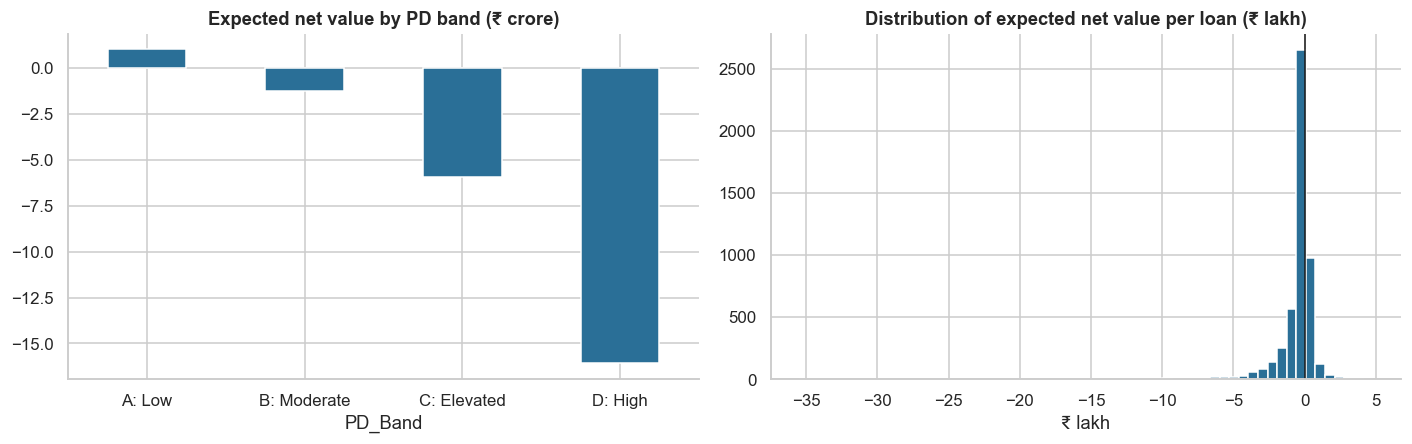

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
data.groupby('PD_Band', observed=True).Expected_Net_Value.sum().div(CRORE).plot(kind='bar', ax=ax[0], color='#2a6f97'); ax[0].set_title('Expected net value by PD band (₹ crore)'); ax[0].tick_params(axis='x', rotation=0)
ax[1].hist(data.Expected_Net_Value / 1e5, bins=60, color='#2a6f97'); ax[1].axvline(0, color='k', lw=1); ax[1].set_title('Distribution of expected net value per loan (₹ lakh)'); ax[1].set_xlabel('₹ lakh')
plt.tight_layout(); savefig('credit_value'); plt.show()

> ### 📘 Explanation — cell 38
> **Decision rule.** (1) Value must be positive; (2) approved book ECL ≤ 3% of exposure. Search the PD cut-off that maximises value within the appetite. Positive-value loans above the cut-off → Review; negative value or PD ≥ 35% → Reject.

## 11. Decision rule: approve, review, reject

Two tests per loan:
1. **Is it worth it?** Expected net value must be positive.
2. **Is the risk inside appetite?** The approved portfolio's ECL must stay at or below **3% of approved exposure** (the shared assumption).

We search the PD cut-off for approval: the highest PD at which the approved book still meets the appetite. Loans that are positive in value but above that cut-off go to **Review** (a credit officer may approve with extra collateral, a shorter term or a higher price). Loans with negative value, or a very high PD, are **Rejected**.

> ### 📘 Explanation — cell 39
> **What it does.** Grid search of approval cut-off from PD 0.05 to 0.39: for each, select loans with PD < cut-off and
> positive value; record count, exposure, ECL ratio, net value. Pick the cut-off with **maximum value among those with ECL
> ratio ≤ 3%**. Plots the risk–return frontier (`credit_frontier.png`).
>
> **Why this method.** It turns a risk-appetite statement into a concrete rule — an efficient frontier of value vs loss
> rate, and the appetite line chooses the point. Transparent and auditable vs a black-box optimisation.
>
> **Output.** **Chosen cut-off PD < 0.11.** At 0.09: 664 loans, ECL 2.4%; at 0.13: 1,009 loans, ECL 3.3% (breaches).
>
> **How to read.** Loosening the cut-off adds value but raises the loss ratio; 0.11 is the last point inside 3%.

Risk appetite: ECL <= 3.0% of approved exposure
Chosen approval cut-off: PD < 0.11


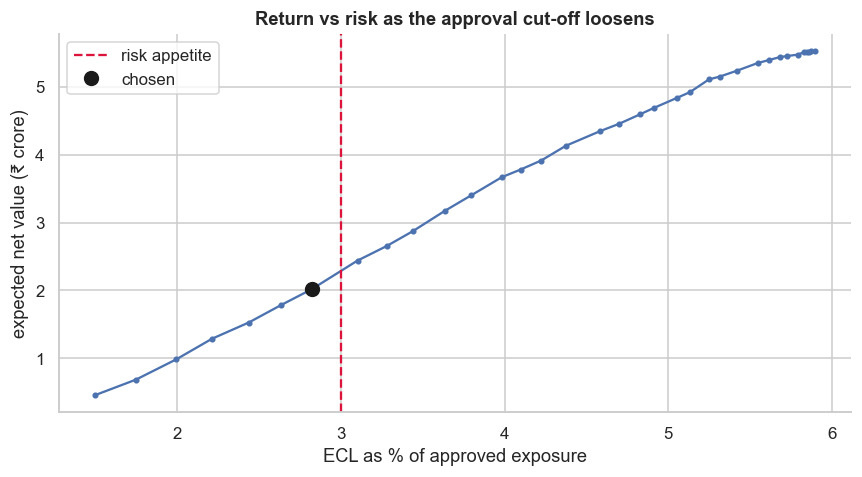

,approve_below_PD,loans,exposure_cr,ecl_ratio,net_value_cr,annual_net_value_cr
0,0.05,218,14.898,0.015,0.456,0.098
4,0.09,664,51.411,0.024,1.527,0.296
8,0.13,1009,89.255,0.033,2.654,0.495
12,0.17,1258,120.295,0.040,3.670,0.662
16,0.21,1422,143.468,0.046,4.348,0.770
20,0.25,1525,159.818,0.051,4.842,0.848
24,0.29,1593,170.640,0.054,5.240,0.909
28,0.33,1632,178.656,0.057,5.456,0.943
32,0.37,1657,181.787,0.059,5.523,0.953


In [22]:
REJECT_PD = 0.35        # D band: PD above 35% is rejected outright
grid = np.round(np.arange(0.05, 0.40, 0.01), 2)
rows = []
for a in grid:
    sel = data[(data.PD < a) & (data.Expected_Net_Value > 0)]
    rows.append({'approve_below_PD': a, 'loans': len(sel), 'exposure_cr': cr(sel.EAD.sum()), 'ecl_ratio': sel.ECL.sum() / sel.EAD.sum(),
                 'net_value_cr': cr(sel.Expected_Net_Value.sum()), 'annual_net_value_cr': cr(sel.Annual_Net_Value.sum())})
frontier = pd.DataFrame(rows)
ok = frontier[frontier.ecl_ratio <= MAX_ECL]
APPROVE_PD = float(ok.loc[ok.net_value_cr.idxmax(), 'approve_below_PD']) if len(ok) else float(grid[0])
print('Risk appetite: ECL <=', f'{MAX_ECL:.1%}', 'of approved exposure')
print('Chosen approval cut-off: PD <', APPROVE_PD)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(frontier.ecl_ratio * 100, frontier.net_value_cr, 'o-', ms=3); ax.axvline(MAX_ECL * 100, color='crimson', ls='--', label='risk appetite')
sel_pt = frontier[frontier.approve_below_PD == APPROVE_PD].iloc[0]; ax.plot(sel_pt.ecl_ratio * 100, sel_pt.net_value_cr, 'ko', ms=9, label='chosen')
ax.set_xlabel('ECL as % of approved exposure'); ax.set_ylabel('expected net value (₹ crore)'); ax.set_title('Return vs risk as the approval cut-off loosens'); ax.legend(); plt.tight_layout(); savefig('credit_frontier'); plt.show()
frontier.round(3).iloc[::4]

> ### 📘 Explanation — cell 40
> **What it does.** Applies the rule to every loan and summarises each decision class.
>
> **Output.** **Approve 836** (₹68.1 cr, ECL 2.82%, mean PD 6.7%, realised default **7.2%**) ·
> **Review 815** (₹113 cr, ECL 7.6%, realised 18.8%) · **Reject 3,349** (₹458.5 cr, value −₹27.8 cr, realised 23.4%).
>
> **How to read.** Realised default is 7% for approved vs 23% for rejected on out-of-fold PDs ⇒ the rule genuinely
> separates good from bad loans. The approved book meets the 3% appetite.

In [23]:
def decide(r):
    if r.Expected_Net_Value <= 0 or r.PD >= REJECT_PD: return 'Reject'
    if r.PD < APPROVE_PD: return 'Approve'
    return 'Review'
data['Decision'] = data.apply(decide, axis=1)
summary = data.groupby('Decision').agg(Loans=('PD', 'size'), **{'Exposure (₹ cr)': ('EAD', lambda s: cr(s.sum())), 'ECL (₹ cr)': ('ECL', lambda s: cr(s.sum())),
                                                                  'Expected net value (₹ cr)': ('Expected_Net_Value', lambda s: cr(s.sum())), 'Mean PD': ('PD', 'mean'), 'Realised default rate': ('Default_Flag', 'mean')})
summary['ECL % of exposure'] = 100 * summary['ECL (₹ cr)'] / summary['Exposure (₹ cr)']
summary.loc[['Approve', 'Review', 'Reject']].round(3)

,Loans,Exposure (₹ cr),ECL (₹ cr),Expected net value (₹ cr),Mean PD,Realised default rate,ECL % of exposure
Decision,,,,,,,
Approve,836,68.140,1.924,2.020,0.067,0.072,2.824
Review,815,112.968,8.632,3.496,0.183,0.188,7.641
Reject,3349,458.545,52.331,-27.780,0.237,0.234,11.412


> ### 📘 Explanation — cell 41
> **What it does.** Exports the brief's required table: Loan ID, Predicted PD, Risk Category (band), EAD, ECL, value, Decision → `credit_decisions.csv`.

In [24]:
# Output table in the format the brief asks for: Loan ID, Predicted PD, Risk Category, Decision
out = data[['Loan_ID', 'Customer_ID', 'Customer_Type', 'PD', 'PD_Band', 'EAD', 'ECL', 'Expected_Net_Value', 'Decision']].rename(columns={'PD': 'Predicted_PD', 'PD_Band': 'Risk_Category'})
out.to_csv(RES / 'credit_decisions.csv', index=False)
out.sort_values('Predicted_PD').head(5)

,Loan_ID,Customer_ID,Customer_Type,Predicted_PD,Risk_Category,EAD,ECL,Expected_Net_Value,Decision
1216,1217,201217,Retail,0.012097,A: Low,780519.28,3776.723887,17566.544655,Approve
3777,3778,203778,Retail,0.014122,A: Low,101510.20,573.419927,1026.255753,Approve
3082,3083,203083,Retail,0.014928,A: Low,260976.16,1558.391808,286.115441,Approve
724,725,200725,Retail,0.016862,A: Low,1017610.19,6863.711694,64116.252556,Approve
4768,4769,204769,Retail,0.017035,A: Low,413959.45,2820.743580,6351.345243,Approve


> ### 📘 Explanation — cell 42
> **Backtest + stress-test motivation.** How fragile is the approved book if PDs rise (recession) or recoveries fall (LGD up)?

**Backtest of the rule.** The table shows the *realised* default rate for each decision class. The approved class should have clearly fewer actual defaults than the rejected one. If it does, the rule separates good from bad loans on data the model never trained on.

## 12. Stress tests
The approval rule was set under base assumptions. How fragile is the approved book if the economy worsens or recoveries are poorer?

> ### 📘 Explanation — cell 43
> **What it does.** Stress grid on the approved book: PD × {1.0, 1.5, 2.0} and LGD ∈ {40%, 50%, 60%} → ECL % of exposure.
> Plus an alternative **collateral-based LGD** = 1 − 0.7 × collateral/EAD (30% haircut), clipped to [5%, 100%].
>
> **Why.** Scenario stress testing is the standard regulatory check (taught); the collateral LGD replaces the flat 40% with a loan-specific estimate.
>
> **Output.** Base 2.82%; PD×1.5 → **4.24%**; PD×2 & LGD 60% → 8.47%. Collateral LGD: mean **0.646**, ECL ratio **4.59%**.
>
> **How to read.** The approved book breaches 3% under moderate stress ⇒ lending needs a capital buffer above expected
> loss (feeds notebook 10's risk view).

In [25]:
appr = data[data.Decision == 'Approve']
scen = []
for pdm in [1.0, 1.5, 2.0]:
    for lgd in [0.40, 0.50, 0.60]:
        ecl = (np.minimum(appr.PD * pdm, 1) * lgd * appr.EAD).sum()
        scen.append({'PD multiplier': pdm, 'LGD': lgd, 'ECL (₹ cr)': cr(ecl), 'ECL % of exposure': 100 * ecl / appr.EAD.sum()})
stress = pd.DataFrame(scen)
display(stress.pivot(index='PD multiplier', columns='LGD', values='ECL % of exposure').round(2))
# collateral-based LGD as an alternative to the flat 40%
haircut = 0.30
alt_lgd = np.clip(1 - haircut * appr.Collateral_Value / appr.EAD, 0.05, 1.0)
alt_ecl = (appr.PD * alt_lgd * appr.EAD).sum()
print('Collateral-based LGD (30% haircut): mean LGD', round(alt_lgd.mean(), 3), '| ECL', f'{cr(alt_ecl):.2f} cr', '| ECL ratio', f'{100*alt_ecl/appr.EAD.sum():.2f}%')

LGD,0.4,0.5,0.6
PD multiplier,,,
1.0,2.82,3.53,4.24
1.5,4.24,5.29,6.35
2.0,5.65,7.06,8.47


Collateral-based LGD (30% haircut): mean LGD 0.646 | ECL 3.13 cr | ECL ratio 4.59%


> ### 📘 Explanation — cell 44
> **What it does.** Recomputes the approved book for cost of funds 4–8%.
>
> **Output.** 4% → 1,329 loans, 1.21% p.a. return; 6% → 836 loans, **0.56%**; 8% → 116 loans, 0.29%.
>
> **How to read.** Lending income is a thin spread over funding cost — the result is very sensitive to the 6% assumption.

In [26]:
# Sensitivity of the approved book to the funding cost (the main income assumption)
def approved_book(cof, approve_pd=APPROVE_PD):
    net_int = interest_income - cof * avg_bal_years
    ev = net_int * (1 - data.PD) - data.ECL
    sel = (data.PD < approve_pd) & (ev > 0)
    return {'cost of funds': cof, 'approved loans': int(sel.sum()), 'exposure (₹ cr)': cr(data.EAD[sel].sum()),
            'annual net value (₹ cr)': cr((ev[sel] / data.Term_Years[sel]).sum()),
            'risk-adjusted return p.a.': (ev[sel] / data.Term_Years[sel]).sum() / data.EAD[sel].sum()}
pd.DataFrame([approved_book(c) for c in [0.04, 0.05, 0.06, 0.07, 0.08]]).set_index('cost of funds').round(4)

,approved loans,exposure (₹ cr),annual net value (₹ cr),risk-adjusted return p.a.
cost of funds,,,,
0.04,1329,109.2975,1.3181,0.0121
0.05,1164,94.3433,0.7970,0.0084
0.06,836,68.1404,0.3824,0.0056
0.07,416,33.4723,0.1305,0.0039
0.08,116,9.8808,0.0288,0.0029


> ### 📘 Explanation — cell 45
> **Reading + limitations** – base case just inside appetite; 1.5× PD shock breaches it. Limitations: synthetic data, default horizon unstated, EAD = full amount, flat LGD, no origination dates (no out-of-time test), governance (monitor drift, recalibrate).

**Reading the grid** (at the default assumptions). The base case (PD ×1.0, LGD 40%) sits just inside the 3% appetite. A 1.5× PD shock lifts the approved book's expected loss to about 4.2% of exposure, which breaches the appetite, and the collateral-based LGD check also lands above 3%. So the lending line needs a capital buffer beyond expected loss.

**Reading the funding-cost table.** Lending income is a thin spread over funding cost, so the result is sensitive to it. Compare the risk-adjusted return per year with what equities and the other lines offer in notebook 10.

## 13. Risks and limitations
- **Synthetic data.** Real portfolios have macro cycles, concentration and data drift that this file does not.
- **Interest rate as a feature.** Dropping it does not change performance (section 4), so pricing leakage is not a concern here. It should still not be reused to set prices.
- **Default horizon is not stated in the file.** The notebook treats `Default_Flag` as a default over the life of the loan and subtracts the full expected loss from lifetime income. If the flag were a one-year default, lifetime losses would be higher and the lending case weaker.
- **Simplified EAD and income.** EAD is the full loan amount (conservative). Interest is lost on default (simplification).
- **LGD is a flat 40%** from the brief. The collateral-based check above shows how much it matters.
- **PD bands and approval cut-off** are judgement calls tied to the 3% risk appetite, which is an assumption. A different appetite moves the cut-off along the frontier.
- **No time dimension.** Loans have no origination date, so the model cannot be tested out of time.
- **Model governance.** In production: monitor PD drift, re-calibrate yearly, keep an overrides log for the Review class and document the rule.

## 14. Export for the allocation (notebook 10)
Lending is split into corporate and retail rows because they are separate lines in the allocation.

> ### 📘 Explanation — cell 46
> **What it does.** Saves `credit.json`: assumptions, chosen model, test/OOF AUC, decision counts and, per line (Corporate,
> Retail), approved loans, exposure, ECL ratio, annual net value, **risk-adjusted return per rupee per year**, stressed ECL
> ratio and review exposure.
>
> **Output.** Corporate: 230 loans, ₹18.8 cr, ECL 2.86%, return 0.61% p.a. · Retail: 606 loans, ₹49.3 cr, ECL 2.81%, return 0.54% p.a.
>
> **Why it matters.** Notebook 10 compares these returns with other lines — lending is thin-margin at these assumptions.

In [27]:
res = {'module': 'credit', 'assumptions': {'LGD': LGD, 'cost_of_funds': COF, 'max_ecl_ratio': MAX_ECL, 'approve_pd_below': APPROVE_PD, 'reject_pd_from': REJECT_PD},
       'model': {'chosen': chosen, 'calibrated': bool(use_cal), 'test_roc_auc': float(binary_report(y_te, final_model.predict_proba(X_te)[:, 1])['ROC-AUC']),
                 'oof_roc_auc': float(binary_report(y, pd_oof)['ROC-AUC'])},
       'decision_counts': data.Decision.value_counts().to_dict(), 'lines': {}}
for line, key in [('Corporate lending', 'Corporate'), ('Retail lending', 'Retail')]:
    a = data[(data.Decision == 'Approve') & (data.Customer_Type == key)]
    allx = data[data.Customer_Type == key]
    res['lines'][line] = {
        'approved_loans': len(a), 'approved_exposure_cr': cr(a.EAD.sum()), 'book_exposure_cr': cr(allx.EAD.sum()),
        'ecl_cr': cr(a.ECL.sum()), 'ecl_ratio': float(a.ECL.sum() / a.EAD.sum()),
        'annual_net_value_cr': cr(a.Annual_Net_Value.sum()),
        'risk_adjusted_return': float(a.Annual_Net_Value.sum() / a.EAD.sum()),     # per year, per rupee of exposure
        'stressed_ecl_ratio_pd1.5_lgd50': float((np.minimum(a.PD * 1.5, 1) * 0.5 * a.EAD).sum() / a.EAD.sum()),
        'review_exposure_cr': cr(allx[allx.Decision == 'Review'].EAD.sum()),
    }
save_result('credit', res)
pd.DataFrame(res['lines']).T.round(4)

saved results/Module_02_Credit_Risk/credit.json


,approved_loans,approved_exposure_cr,book_exposure_cr,ecl_cr,ecl_ratio,annual_net_value_cr,risk_adjusted_return,stressed_ecl_ratio_pd1.5_lgd50,review_exposure_cr
Corporate lending,230.0,18.8179,173.2242,0.5380,0.0286,0.1146,0.0061,0.0536,28.3253
Retail lending,606.0,49.3225,466.4287,1.3862,0.0281,0.2678,0.0054,0.0527,84.6423


> ### 📘 Explanation — cell 47
> **Headline results** – ready-made summary for the report (model AUC, book ECL 9.8%, decisions, ~0.5–0.6% return).

## Headline results (default assumptions)
- **Model.** Logistic regression, test ROC-AUC about 0.75 (out-of-fold on the full book about 0.73). The three models are statistically indistinguishable, so the transparent one is used. PDs are well calibrated and the bands show realised default rates rising from about 7% to 47%.
- **Whole book.** About ₹640 crore of exposure, expected credit loss about ₹63 crore (9.8% of exposure). About two thirds of loans have negative expected net value after expected losses and funding cost.
- **Decision.** 836 loans approved (about ₹68 crore, expected loss 2.8%, realised default rate 7%), 815 sent to review (about ₹113 crore) and 3,349 rejected (realised default rate 23%).
- **Return.** The approved book earns only about 0.5% to 0.6% per year after expected losses, so lending is capital-light on volume and thin on margin at these assumptions. That is an input to the allocation, not a verdict by itself.

## Status
Notebook 02 is complete when the cell above saves `results/credit.json` and `results/credit_decisions.csv`. Next: **01 Strategic initiatives**.